# Agricultural production

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import f


In [2]:
drip = np.array([42,45,43,46,44,45])
sprinkler = np.array([38,40,39,41,38,42])
flood = np.array([35,37,36,34,33,35])
df = pd.DataFrame({"Drip":drip,"Sprinkler":sprinkler,"Flood":flood})
df

,Drip,Sprinkler,Flood
0,42,38,35
1,45,40,37
2,43,39,36
3,46,41,34
4,44,38,33
5,45,42,35


In [3]:
k = 3 
N = len(df) * k
dof_between = k -1
dof_within = N - k
dof_total = dof_between + dof_within
print("Degree of freedom between : ",dof_between)
print("Degree of  freedom within  : ",dof_within)
print("Degree of freedom total : ",dof_total)

Degree of freedom between :  2
Degree of  freedom within  :  15
Degree of freedom total :  17


In [5]:
mean_of_drip = df["Drip"].mean()
mean_of_sprinkler = df["Sprinkler"].mean()
mean_of_flood = df["Flood"].mean()
grand_mean = df.mean().mean()
print("Average of Drip : ",mean_of_drip)
print("Average of Sprinkler : ",mean_of_sprinkler)
print("Average of Flood : ",mean_of_flood)
print("Total Average : ",grand_mean)

Average of Drip :  44.166666666666664
Average of Sprinkler :  39.666666666666664
Average of Flood :  35.0
Total Average :  39.61111111111111


In [6]:
ss_between = len(df["Drip"]) * (mean_of_drip - grand_mean)** 2 + len(df["Flood"]) * (mean_of_flood - grand_mean)** 2 + len(df["Sprinkler"])*(mean_of_sprinkler - grand_mean)** 2 
print("sum of square between : ",ss_between)

sum of square between :  252.11111111111097


In [8]:
ss_within = ((df["Drip"]-mean_of_drip)** 2 ).sum() + ((df["Flood"] - mean_of_flood) ** 2).sum() + ((df["Sprinkler"] - mean_of_sprinkler)** 2 ).sum()
print("sum of square within : ",ss_within)

sum of square within :  34.166666666666664


In [9]:
mean_square_between = ss_between / dof_between
mean_square_within = ss_within / dof_within
f_test = mean_square_between / mean_square_within
print("mean square between : ",mean_square_between)
print("mean square within : ",mean_square_within)
print("F test stats : ",f_test )

mean square between :  126.05555555555549
mean square within :  2.2777777777777777
F test stats :  55.34146341463412


In [14]:
alpha = 0.05
critical_value = f.ppf(1-alpha ,dof_between,dof_within)
p_value = f.sf(f_test,dof_between,dof_within)
print("Critical value : ",critical_value)
print("p value : ",p_value)


Critical value :  3.682320343673241
p value :  1.1915500791883763e-07


In [13]:
if p_value < alpha :
    print("Decison : we reject the null hypothesis .")
else:
    print("Decision : we are fail to reject the null hypothesis .")

Decison : we reject the null hypothesis .


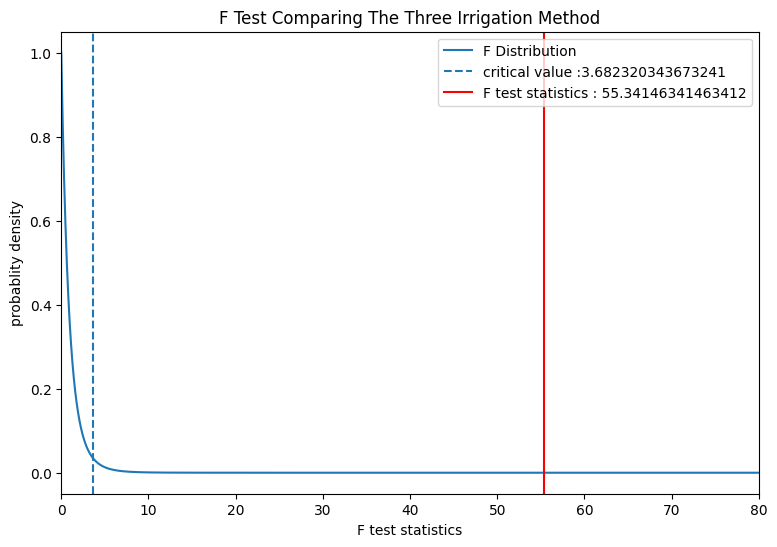

In [25]:
x = np.linspace(0,80,1000)
y = f.pdf(x,dof_between,dof_within)
plt.figure(figsize=(9,6))
plt.plot(x,y,label="F Distribution")
plt.axvline(critical_value,linestyle="--",label=f"critical value :{critical_value} ")
plt.axvline(f_test,linestyle="solid",color = "red",label = f"F test statistics : {f_test}")
plt.xlim(0,80)
plt.title("F Test Comparing The Three Irrigation Method")
plt.xlabel("F test statistics")
plt.ylabel("probablity density")
plt.legend()
plt.show()
